# Model A: training experiments and results

Explore a saved poker experiment, adjust its training parameters, and compare
the untrained and trained policies. This notebook uses the same `train.py`
and `evaluate.py` as the command line, so there is one training implementation.

**Start here:** select the repository's **.venv / Python 3.12** kernel and
run all cells. By default this only reads the saved `notebook_baseline_seed7` run.
All charts below are based on saved measurements, not illustrative data.

**To train:** edit the settings in section 1, set `RUN_NEW_TRAINING = True`,
and run from that cell onward. A fresh experiment directory is created each
time the training cell runs with that switch enabled. Set the switch back
to `False` afterward and set `EXISTING_RUN` to the printed folder name.

**To evaluate:** set `RUN_EVALUATION = True`. This compares the saved initial
and trained policies and saves a new report without overwriting old reports.
Restart the kernel after editing imported Python modules.

In [1]:
import json
import sys
from datetime import datetime
from pathlib import Path

# Locate the repository whether Jupyter starts here or in notebooks/.
candidates = (Path.cwd(), *Path.cwd().parents)
ROOT = next((p for p in candidates if (p / "bluffbot" / "env.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from the bluffbot repository.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

from bluffbot.actions import Action
from bluffbot.evaluate import BENCHMARK_NAMES, compare
from bluffbot.train import train

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.2})
pd.set_option("display.max_colwidth", 80)
print("Repository:", ROOT)
print("Python:", sys.executable)

Repository: /Users/qxd/Programming/bluffbot
Python: /Users/qxd/Programming/bluffbot/.venv/bin/python


## 1. Edit your experiment settings here

These settings apply only when starting a **new** run. They do not change an
existing policy or relabel its saved results.

| Setting | Meaning |
|---|---|
| `decisions`, `seed` | Target actual poker decisions; reproducible experiment seed |
| `opponent` | `mixture`, `random`, `check_call`, `tight`, or `aggressive` |
| `policy_layers`, `value_layers` | Neurons in each hidden layer of actor and critic |
| `learning_rate` | Size of optimizer updates; start at `0.0003` |
| `n_steps` | Environment steps collected per rollout, including forced acknowledgements |
| `batch_size`, `n_epochs` | Examples per update and training passes over each rollout |
| `gamma` | Reward discount; keep `1.0` for undiscounted profit per hand |
| `gae_lambda` | Advantage estimation tradeoff; start at `0.95` |
| `clip_range` | PPO probability-ratio clipping; start at `0.2` |
| `ent_coef` | Extra incentive for action diversity; default `0.0` |

Use a batch size that divides `n_steps`, and change one setting at a time.
The actual decision target rounds up to a complete rollout. Keep evaluation
seeds fixed when comparing settings; repeat promising settings with several
training seeds. Reserve different seeds/opponents for a later final test.

In [2]:
RUN_NEW_TRAINING = False
RUN_EVALUATION = False

EXISTING_RUN = "notebook_baseline_seed7"  # A folder under runs/, or an absolute path.
EXPERIMENT_LABEL = "notebook"     # Prefix for new run directories.
EVALUATION_FILE = None            # None = latest saved evaluation*.json in the run.

TRAINING_CONFIG = {
    "decisions": 10_000,
    "seed": 7,
    "opponent": "mixture",
    "policy_layers": [128, 128],
    "value_layers": [128, 128],
    "learning_rate": 0.0003,
    "n_steps": 256,
    "batch_size": 64,
    "n_epochs": 10,
    "gamma": 1.0,
    "gae_lambda": 0.95,
    "clip_range": 0.2,
    "ent_coef": 0.0,
}

EVALUATION_CONFIG = {
    "sessions": 5,
    "hands": 500,                 # Hands per session, per opponent, per policy.
    "seed": 1000,
    "opponents": list(BENCHMARK_NAMES),
}
SMOOTHING_ROLLOUTS = 5            # Only changes the training-profit chart.

display(pd.Series(TRAINING_CONFIG, name="New training settings").to_frame())
total_hands = (2 * EVALUATION_CONFIG["sessions"] * EVALUATION_CONFIG["hands"]
               * len(EVALUATION_CONFIG["opponents"]))
print(f"Evaluation workload: {total_hands:,} hands across two policies.")

Evaluation workload: 30,000 hands across two policies.


,New training settings
decisions,10000
seed,7
opponent,mixture
policy_layers,"[128, 128]"
value_layers,"[128, 128]"
learning_rate,0.0003
n_steps,256
batch_size,64
n_epochs,10
gamma,1.0


## 2. Choose a saved run or start a new one

The table lists completed experiments. New runs save their full configuration,
initial policy, trained policy, summary, and TensorBoard metrics. Reading a
saved run does not resume training or update its model.

In [3]:
inventory = []
for path in sorted((ROOT / "runs").glob("*/training_summary.json")):
    saved = json.loads(path.read_text())
    inventory.append({"run": path.parent.name, "seed": saved["seed"],
                      "decisions": saved["learner_decisions"],
                      "hands": saved["completed_hands"],
                      "seconds": round(saved["elapsed_seconds"], 2)})
display(pd.DataFrame(inventory))

if RUN_NEW_TRAINING:
    if not EXPERIMENT_LABEL or any(c not in "abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789_-"
                                   for c in EXPERIMENT_LABEL):
        raise ValueError("Use letters, digits, underscores, or hyphens in EXPERIMENT_LABEL.")
    stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    run_dir = ROOT / "runs" / f"{EXPERIMENT_LABEL}_{stamp}"
    run_dir = train(output=run_dir, **TRAINING_CONFIG)
else:
    run_dir = Path(EXISTING_RUN).expanduser()
    if not run_dir.is_absolute():
        run_dir = ROOT / "runs" / run_dir

if not (run_dir / "training_summary.json").is_file():
    raise FileNotFoundError(f"No completed run at {run_dir}. Select a listed run or enable training.")
print("Selected run:", run_dir)

Selected run: /Users/qxd/Programming/bluffbot/runs/notebook_baseline_seed7


,run,seed,decisions,hands,seconds
0,notebook_baseline_seed7,7,10039,5564,8.30
1,section5_seed7,7,10039,5564,7.97


In [4]:
summary = json.loads((run_dir / "training_summary.json").read_text())
keys = ["seed", "requested_learner_decisions", "learner_decisions", "interface_steps",
        "completed_hands", "zero_decision_hands", "elapsed_seconds",
        "learner_decisions_per_second", "reload_check_passed"]
display(pd.Series({k: summary.get(k) for k in keys}, name="Saved run summary").to_frame())

config_path = run_dir / "training_config.json"
saved_config = (json.loads(config_path.read_text()) if config_path.exists()
                else summary.get("training_parameters"))
if saved_config is None:
    saved_config = {k: summary[k] for k in ("seed", "network", "gamma") if k in summary}
    print("Older run: only the settings below were saved; other parameters are unknown here.")
display(pd.Series(saved_config, name="Settings actually used for this run").to_frame())

,Saved run summary
seed,7
requested_learner_decisions,10000
learner_decisions,10039
interface_steps,10752
completed_hands,5564
zero_decision_hands,713
elapsed_seconds,8.30479
learner_decisions_per_second,1208.820525
reload_check_passed,True


,Settings actually used for this run
decisions,10000
seed,7
opponent,mixture
policy_layers,"[128, 128]"
value_layers,"[128, 128]"
learning_rate,0.0003
n_steps,256
batch_size,64
n_epochs,10
gamma,1.0


## 3. Training progress

The horizontal axis uses **actual learner decisions**, excluding forced
terminal acknowledgements. Cumulative profit and rolling BB/100 include
every completed hand, including hands won before the learner acts.
The rolling window spans the selected number of logged rollouts.

These curves describe a policy that changes during training. They are useful
for debugging, but fixed-checkpoint evaluation in section 5 is the comparison
to use when deciding whether a trained policy improved.

In [5]:
def read_training_history(directory):
    rows = []
    event_dirs = sorted({p.parent for p in (directory / "tensorboard").rglob("events.out.tfevents.*")})
    for event_dir in event_dirs:
        accumulator = EventAccumulator(str(event_dir), size_guidance={"scalars": 0})
        accumulator.Reload()
        for tag in accumulator.Tags()["scalars"]:
            for event in accumulator.Scalars(tag):
                rows.append({"step": event.step, "wall_time": event.wall_time,
                             "metric": tag, "value": event.value})
    if not rows:
        return pd.DataFrame()
    events = (pd.DataFrame(rows).sort_values("wall_time")
              .drop_duplicates(["step", "metric"], keep="last"))
    return events.pivot(index="step", columns="metric", values="value").sort_index()

history = read_training_history(run_dir)
if history.empty:
    print("No TensorBoard scalar data was found. Summary and evaluation panels still work.")
else:
    display(history.tail(5))

def plot_metric(ax, metric, title, ylabel, transform=None):
    if history.empty or metric not in history:
        ax.text(0.5, 0.5, "Metric not saved in this run", ha="center", va="center",
                transform=ax.transAxes)
    else:
        values = history[metric].dropna()
        x = history["poker/learner_decisions"].ffill().reindex(values.index)
        ax.plot(x, transform(values) if transform else values, linewidth=1.8)
    ax.set(title=title, xlabel="Learner decisions", ylabel=ylabel)

metric,poker/completed_hands,poker/learner_decisions,poker/profit_bb,poker/zero_decision_hands,rollout/ep_len_mean,rollout/ep_rew_mean,time/fps,train/approx_kl,train/clip_fraction,train/clip_range,train/entropy_loss,train/explained_variance,train/learning_rate,train/loss,train/policy_gradient_loss,train/value_loss
step,,,,,,,,,,,,,,,,
9728,5122.0,9067.0,2020.0,661.0,1.93,3.960,1633.0,0.007887,0.092578,0.2,-1.174482,-0.000968,0.0003,2499.713623,-0.012228,5228.710938
9984,5220.0,9311.0,2001.0,673.0,2.58,-0.100,1619.0,0.010985,0.096875,0.2,-1.253058,-0.001635,0.0003,2385.559570,-0.015848,4680.036133
10240,5335.0,9548.0,2058.0,692.0,2.15,-1.405,1645.0,0.007250,0.071875,0.2,-1.193278,0.007364,0.0003,1557.412109,-0.013443,4123.342773
10496,5456.0,9790.0,2021.0,706.0,2.04,0.050,1671.0,0.011750,0.083594,0.2,-1.257423,0.008545,0.0003,2239.496094,-0.013515,3789.499268
10752,5564.0,10039.0,1854.0,713.0,2.33,-3.660,1608.0,0.009871,0.085547,0.2,-1.156200,-0.004608,0.0003,2360.216064,-0.012428,5306.109375


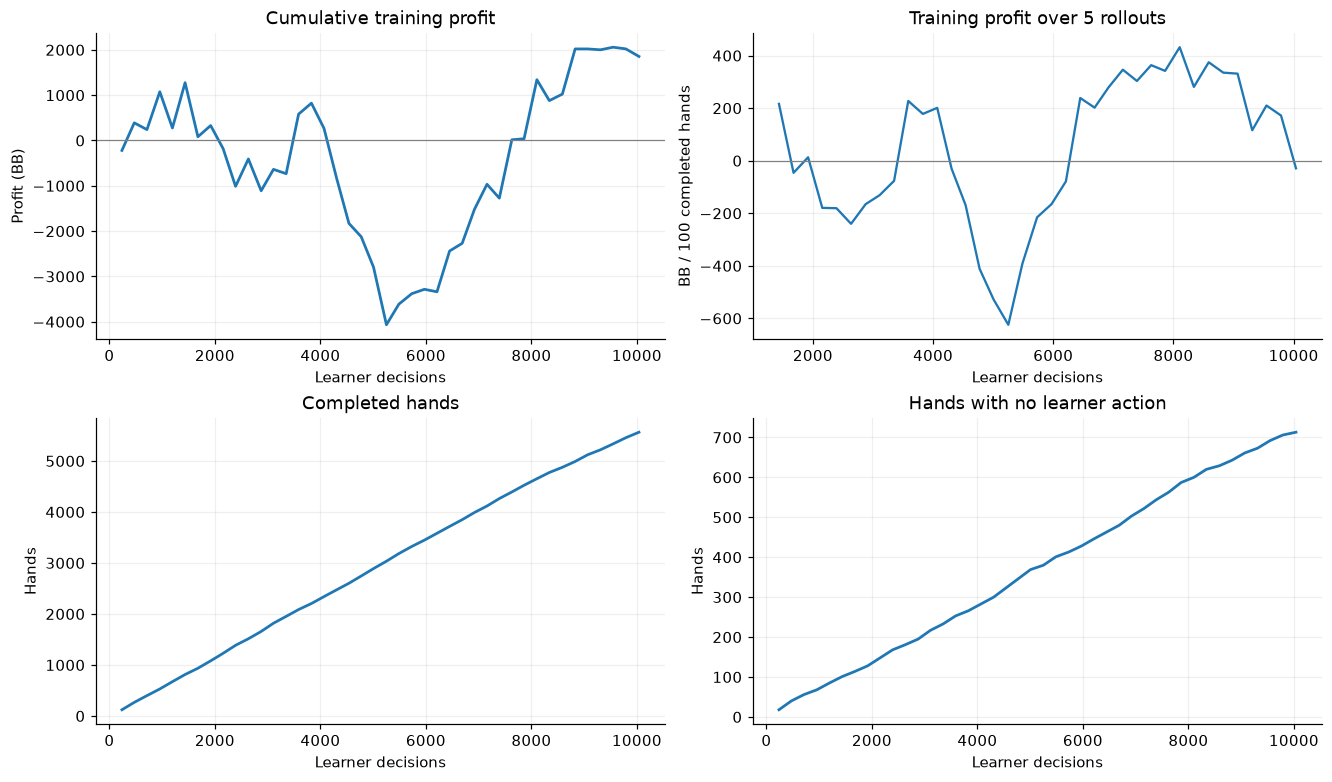

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), constrained_layout=True)
plot_metric(axes[0, 0], "poker/profit_bb", "Cumulative training profit", "Profit (BB)")
axes[0, 0].axhline(0, color="grey", linewidth=0.8)

if not history.empty and {"poker/profit_bb", "poker/completed_hands"}.issubset(history.columns):
    window = max(1, int(SMOOTHING_ROLLOUTS))
    rolling_rate = (100 * history["poker/profit_bb"].diff(window)
                    / history["poker/completed_hands"].diff(window).replace(0, np.nan))
    axes[0, 1].plot(history["poker/learner_decisions"], rolling_rate)
axes[0, 1].axhline(0, color="grey", linewidth=0.8)
axes[0, 1].set(title=f"Training profit over {SMOOTHING_ROLLOUTS} rollouts",
               xlabel="Learner decisions", ylabel="BB / 100 completed hands")
plot_metric(axes[1, 0], "poker/completed_hands", "Completed hands", "Hands")
plot_metric(axes[1, 1], "poker/zero_decision_hands", "Hands with no learner action", "Hands")
plt.show()

## 4. What changed inside PPO?

**Value loss** measures critic prediction error; **policy loss** is the actor's
optimization objective, not chip profit. **Entropy** measures action diversity;
lower entropy means more concentrated choices among the available actions.
**Approximate KL** measures how much the action distribution changed during
updates. None of these alone measures poker skill.

The original `section5_seed7` run did not retain optimizer diagnostics. Those
panels say so explicitly. New runs from the updated runner record them.

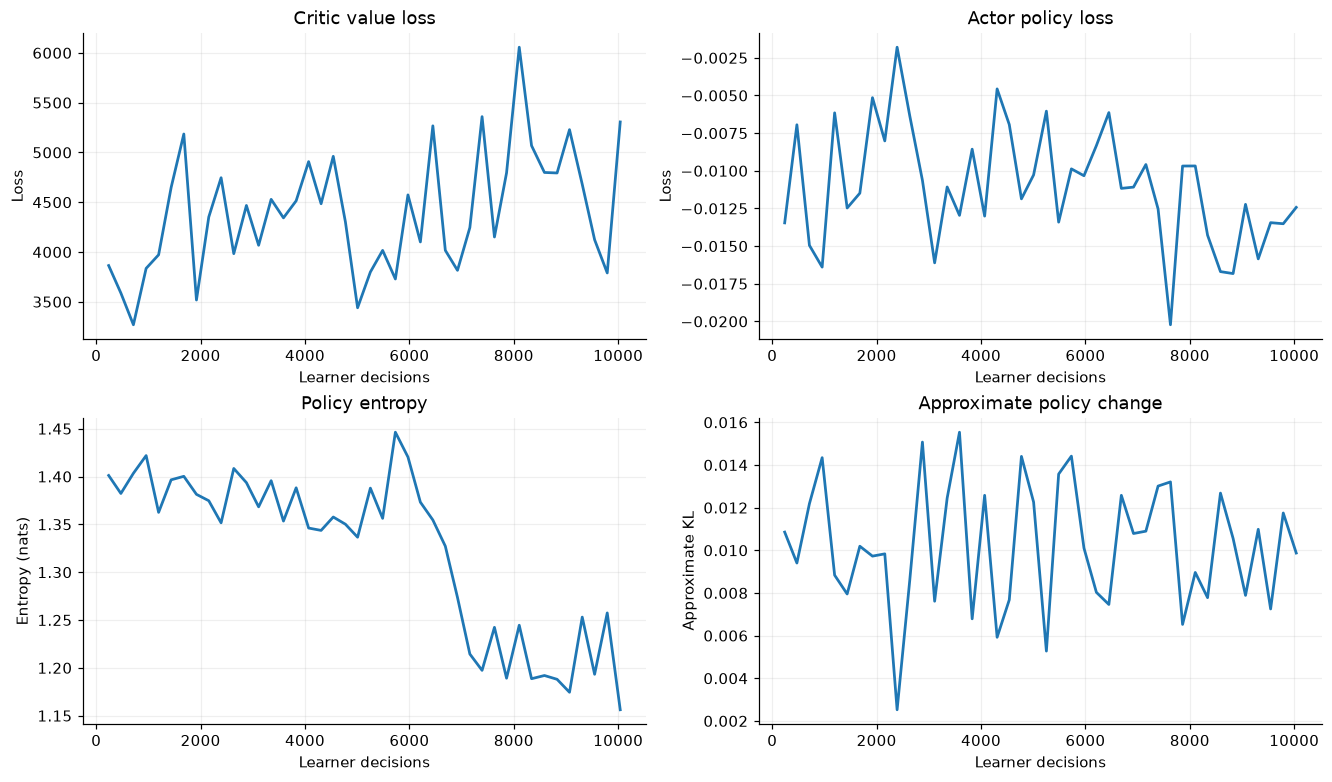

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), constrained_layout=True)
plot_metric(axes[0, 0], "train/value_loss", "Critic value loss", "Loss")
plot_metric(axes[0, 1], "train/policy_gradient_loss", "Actor policy loss", "Loss")
plot_metric(axes[1, 0], "train/entropy_loss", "Policy entropy", "Entropy (nats)", transform=lambda y: -y)
plot_metric(axes[1, 1], "train/approx_kl", "Approximate policy change", "Approximate KL")
plt.show()

## 5. Evaluate the saved policies

With `RUN_EVALUATION = False`, load the latest saved evaluation in this run,
or choose one with `EVALUATION_FILE`. If no report exists, the remaining
charts explain how to generate one rather than inventing results.

With the switch enabled, compare the **same saved untrained and trained
policies**, using masked, sampled actions and matching evaluation seeds.
A new timestamped JSON report stores results and the requested settings.
The held-out variants belong to the same simple bot families used in training;
they are modest diagnostics, not an independent strong poker benchmark.

In [8]:
if RUN_EVALUATION:
    report = compare([run_dir / "untrained.zip", run_dir / "trained.zip"], **EVALUATION_CONFIG)
    report["evaluation_parameters"] = EVALUATION_CONFIG
    report["run_directory"] = str(run_dir)
    stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    report_path = run_dir / f"evaluation_{stamp}.json"
    with report_path.open("x") as handle:
        handle.write(json.dumps(report, indent=2) + "\n")
else:
    if EVALUATION_FILE:
        report_path = Path(EVALUATION_FILE).expanduser()
        if not report_path.is_absolute():
            report_path = run_dir / report_path
    else:
        reports = list(run_dir.glob("evaluation*.json"))
        report_path = max(reports, key=lambda p: p.stat().st_mtime_ns) if reports else None
    report = json.loads(report_path.read_text()) if report_path else None

if report is None:
    print("No saved evaluation. Set RUN_EVALUATION = True and rerun this cell onward.")
else:
    print("Evaluation report:", report_path)
    # Labels come from checkpoint filenames, not assumptions about report order.
    evaluation_rows = []
    for checkpoint, results in report["checkpoints"].items():
        for result in results:
            interval = result["session_bootstrap_95_interval"]
            evaluation_rows.append({
                "policy": Path(checkpoint).stem, "opponent": result["opponent"],
                "bb_per_100": result["bb_per_100"],
                "low": interval[0] if interval is not None else np.nan,
                "high": interval[1] if interval is not None else np.nan,
                "sessions": result["sessions"], "hands_per_session": result["hands_per_session"],
                "first_session_seed": result["first_session_seed"],
                "illegal_action_rate": result["illegal_action_rate"],
                "zero_decision_hands": result["zero_decision_hands"],
            })
    evaluation = pd.DataFrame(evaluation_rows)
    display(evaluation.round(3))

Evaluation report: /Users/qxd/Programming/bluffbot/runs/notebook_baseline_seed7/evaluation.json


,policy,opponent,bb_per_100,low,high,sessions,hands_per_session,first_session_seed,illegal_action_rate,zero_decision_hands
0,untrained,random,-9.86,-188.08,157.000,5,500,1000,0.0,257
1,untrained,check_call,-135.10,-321.88,6.840,5,500,1000,0.0,0
2,untrained,tight,-428.08,-547.92,-315.000,5,500,1000,0.0,1006
3,untrained,aggressive,-512.54,-765.70,-165.540,5,500,1000,0.0,0
4,untrained,heldout_passive,-87.02,-297.22,236.500,5,500,1000,0.0,47
5,untrained,heldout_aggressive,-579.20,-760.38,-372.640,5,500,1000,0.0,0
6,trained,random,322.32,254.84,418.060,5,500,1000,0.0,235
7,trained,check_call,-80.94,-326.32,101.754,5,500,1000,0.0,0
8,trained,tight,-448.50,-508.42,-388.580,5,500,1000,0.0,1006
9,trained,aggressive,-306.40,-526.56,-79.940,5,500,1000,0.0,0


### Profit by opponent, with uncertainty

Dots are mean BB/100; horizontal lines are 95% bootstrap intervals formed by
resampling **whole sessions**. Five sessions give preliminary uncertainty
estimates. An interval crossing zero does not establish profitability.

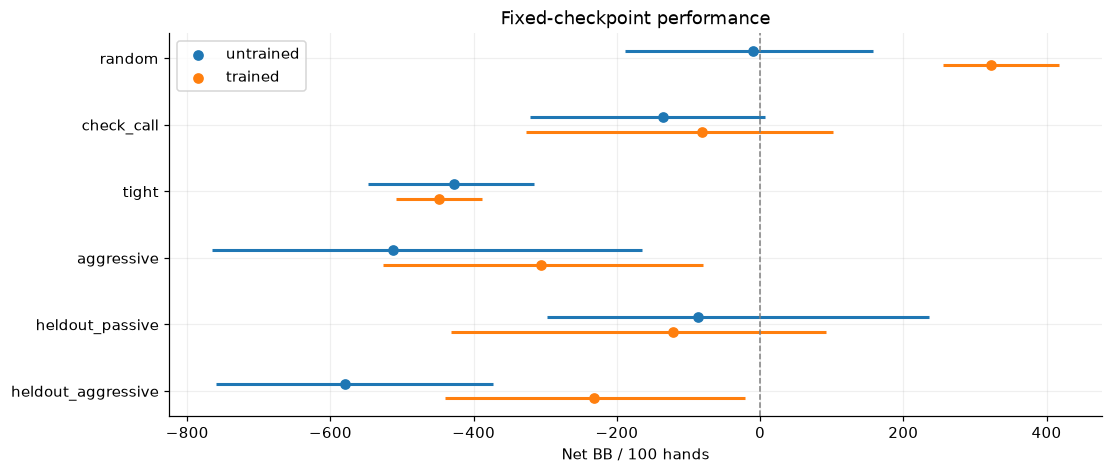

In [9]:
if report is not None:
    names = list(dict.fromkeys(evaluation["opponent"]))
    policies = list(dict.fromkeys(evaluation["policy"]))
    fig, ax = plt.subplots(figsize=(10, max(4, 0.7 * len(names))), constrained_layout=True)
    y = np.arange(len(names))
    for i, policy in enumerate(policies):
        data = evaluation[evaluation["policy"] == policy].set_index("opponent").reindex(names)
        offset = (i - (len(policies) - 1) / 2) * 0.22
        marks = ax.scatter(data["bb_per_100"], y + offset, label=policy, zorder=3)
        color = marks.get_facecolor()[0]
        ax.hlines(y + offset, data["low"], data["high"], color=color, linewidth=2)
    ax.axvline(0, color="grey", linestyle="--", linewidth=1)
    ax.set(yticks=y, yticklabels=names, xlabel="Net BB / 100 hands", title="Fixed-checkpoint performance")
    ax.invert_yaxis()
    ax.legend()
    plt.show()

### Improvement over the starting policy

Positive means the trained policy earned more than its untrained starting
point. These intervals use **paired session differences** on the same seeds,
rather than subtracting the endpoints of the previous chart. Improvement can
coexist with an overall losing policy.

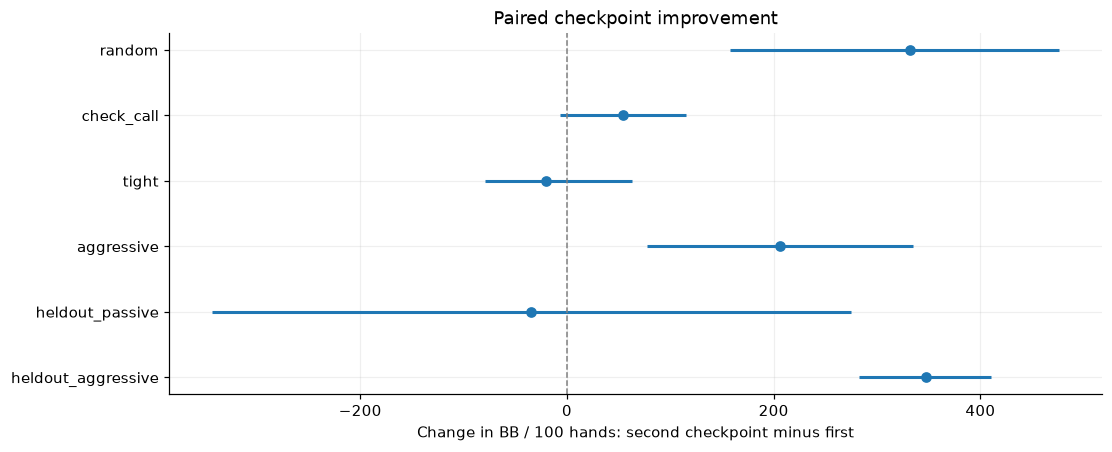

In [10]:
if report is not None and report.get("paired_differences"):
    differences = pd.DataFrame(report["paired_differences"])
    fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
    y = np.arange(len(differences))
    ax.scatter(differences["bb_per_100_change"], y, zorder=3)
    for i, row in differences.iterrows():
        interval = row["session_bootstrap_95_interval"]
        if interval is not None:
            ax.hlines(i, interval[0], interval[1], linewidth=2)
    ax.axvline(0, color="grey", linestyle="--", linewidth=1)
    ax.set(yticks=y, yticklabels=differences["opponent"],
           xlabel="Change in BB / 100 hands: second checkpoint minus first",
           title="Paired checkpoint improvement")
    ax.invert_yaxis()
    plt.show()

## 6. How did the policy play?

Action percentages below pool counts across all evaluated hands for each
policy. They exclude forced acknowledgements. Different opponents create
different decision opportunities, so action frequency alone is not a measure
of strategy quality. Raise-to sizes are total current-street bets, not extra
chips added; the chart normalizes within raising actions only.

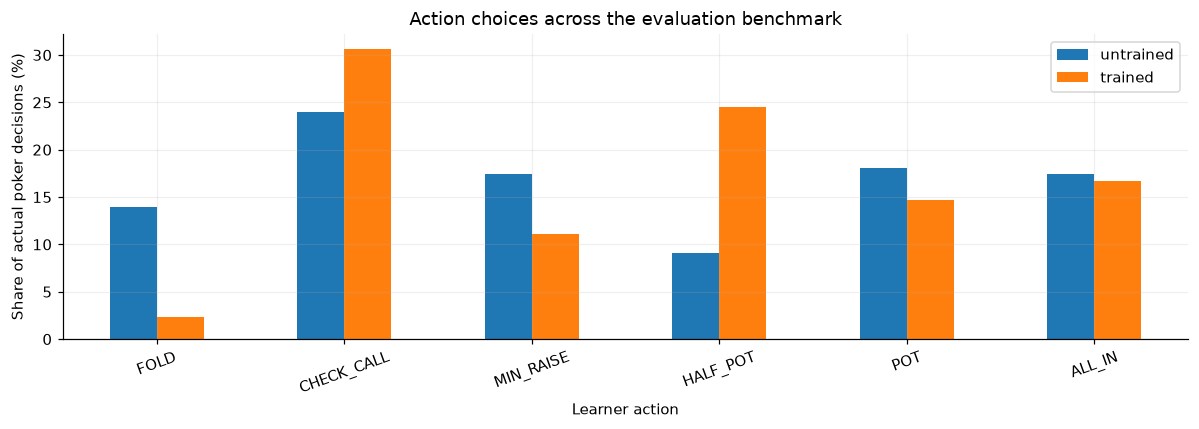

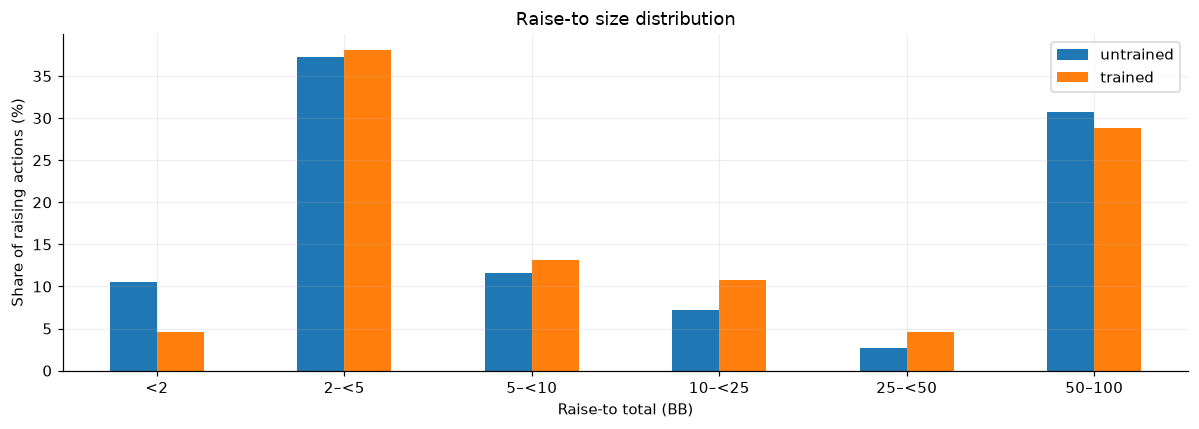

In [11]:
if report is not None:
    action_names = [action.name for action in Action]
    pooled = {}
    for checkpoint, results in report["checkpoints"].items():
        counts = pd.Series({name: sum(r["action_counts"][name] for r in results) for name in action_names})
        pooled[Path(checkpoint).stem] = 100 * counts / max(1, counts.sum())
    action_percentages = pd.DataFrame(pooled).reindex(action_names)
    ax = action_percentages.plot.bar(figsize=(11, 4), rot=20)
    ax.set(title="Action choices across the evaluation benchmark",
           xlabel="Learner action", ylabel="Share of actual poker decisions (%)")
    plt.tight_layout()
    plt.show()

    edges = np.array([0, 2, 5, 10, 25, 50, 101])
    size_labels = ["<2", "2–<5", "5–<10", "10–<25", "25–<50", "50–100"]
    sizes = {}
    for checkpoint, results in report["checkpoints"].items():
        amounts, weights = [], []
        for result in results:
            for amount, count in result["raise_to_bb_counts"].items():
                amounts.append(float(amount))
                weights.append(count)
        counts, _ = np.histogram(amounts, bins=edges, weights=weights)
        sizes[Path(checkpoint).stem] = 100 * counts / max(1, counts.sum())
    ax = pd.DataFrame(sizes, index=size_labels).plot.bar(figsize=(11, 4), rot=0)
    ax.set(title="Raise-to size distribution", xlabel="Raise-to total (BB)",
           ylabel="Share of raising actions (%)")
    plt.tight_layout()
    plt.show()

## 7. Position and accounting checks

Heads-up positions alternate every hand. Position results include hands
ending before any learner action. A completed evaluation must have zero
illegal actions; the evaluator raises an error if one occurs.

All loaded evaluation results report zero illegal actions.


,policy,position,hands,bb_per_100
0,untrained,button,7500,-405.93
1,untrained,big_blind,7500,-178.00
2,trained,button,7500,-226.67
3,trained,big_blind,7500,-62.25


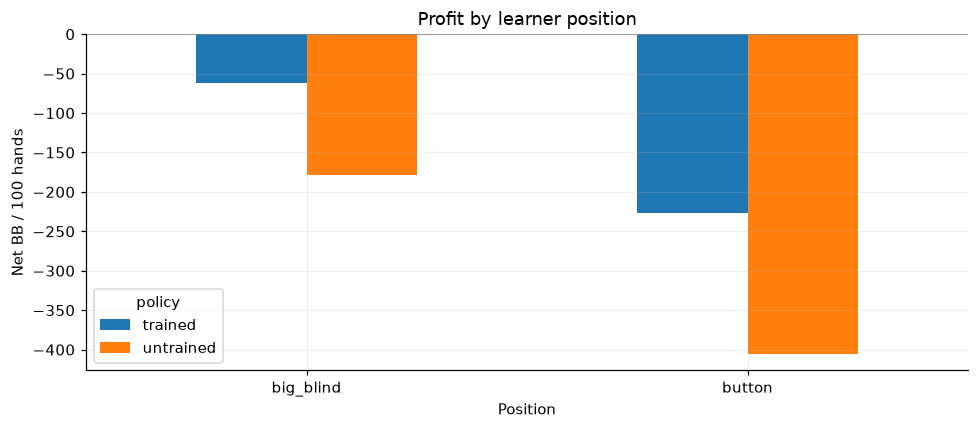

In [12]:
if report is not None:
    position_rows = []
    for checkpoint, results in report["checkpoints"].items():
        for position in ("button", "big_blind"):
            hands = sum(r["positions"][position]["hands"] for r in results)
            profit = sum(r["positions"][position]["profit_bb"] for r in results)
            position_rows.append({"policy": Path(checkpoint).stem, "position": position,
                                  "hands": hands, "bb_per_100": 100 * profit / hands if hands else np.nan})
    positions = pd.DataFrame(position_rows)
    display(positions.round(2))
    ax = positions.pivot(index="position", columns="policy", values="bb_per_100").plot.bar(
        figsize=(9, 4), rot=0)
    ax.axhline(0, color="grey", linewidth=1)
    ax.set(title="Profit by learner position", xlabel="Position", ylabel="Net BB / 100 hands")
    plt.tight_layout()
    plt.show()
    assert (evaluation["illegal_action_rate"] == 0).all()
    print("All loaded evaluation results report zero illegal actions.")

## 8. Compare experiments

This table finds saved reports across `runs/`, including future experiments.
Compare rows only when the opponent, evaluation seed, sessions, and hands per
session match. Training seeds may differ intentionally. A single promising
seed is not evidence of repeatable improvement.

In [13]:
experiment_rows = []
for summary_path in sorted((ROOT / "runs").glob("*/training_summary.json")):
    run_summary = json.loads(summary_path.read_text())
    for path in sorted(summary_path.parent.glob("evaluation*.json")):
        saved_report = json.loads(path.read_text())
        for checkpoint, results in saved_report["checkpoints"].items():
            if Path(checkpoint).stem != "trained":
                continue
            for result in results:
                experiment_rows.append({
                    "run": summary_path.parent.name, "report": path.name,
                    "training_seed": run_summary["seed"],
                    "decisions": run_summary["learner_decisions"],
                    "opponent": result["opponent"], "bb_per_100": result["bb_per_100"],
                    "evaluation_seed": result["first_session_seed"],
                    "sessions": result["sessions"], "hands_per_session": result["hands_per_session"],
                })
experiment_comparison = pd.DataFrame(experiment_rows)
display(experiment_comparison.round(2) if not experiment_comparison.empty else experiment_comparison)

,run,report,training_seed,decisions,opponent,bb_per_100,evaluation_seed,sessions,hands_per_session
0,notebook_baseline_seed7,evaluation.json,7,10039,random,322.32,1000,5,500
1,notebook_baseline_seed7,evaluation.json,7,10039,check_call,-80.94,1000,5,500
2,notebook_baseline_seed7,evaluation.json,7,10039,tight,-448.50,1000,5,500
3,notebook_baseline_seed7,evaluation.json,7,10039,aggressive,-306.40,1000,5,500
4,notebook_baseline_seed7,evaluation.json,7,10039,heldout_passive,-121.48,1000,5,500
5,notebook_baseline_seed7,evaluation.json,7,10039,heldout_aggressive,-231.76,1000,5,500
6,section5_seed7,evaluation.json,7,10039,random,322.32,1000,5,500
7,section5_seed7,evaluation.json,7,10039,check_call,-80.94,1000,5,500
8,section5_seed7,evaluation.json,7,10039,tight,-448.50,1000,5,500
9,section5_seed7,evaluation.json,7,10039,aggressive,-306.40,1000,5,500


**Suggested next experiment:** keep the evaluation settings fixed, change
only the training decision budget from 10,000 to 50,000, and compare results.
Then repeat with different training seeds. Keep the saved initial policy for
every run, especially when changing network size or initialization seed.

This notebook covers the heads-up baseline. It does not add checkpoint
self-play, multiplayer gameplay, or a stronger independent benchmark.